In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.offline as py
import plotly.graph_objects as go
import plotly.tools as tls

In [2]:
matches = pd.read_csv('matches.csv')
delivery = pd.read_csv('deliveries.csv')


In [3]:
matches.head()

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,NaN
2,3,2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN
4,5,2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,NaN


In [4]:
delivery.head()

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
0,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,1,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
1,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,2,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
2,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,3,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,4,0,4,NaN,NaN,NaN
3,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,4,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
4,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,5,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,2,2,NaN,NaN,NaN


In [5]:
matches.info()

<class 'pandas.DataFrame'>
RangeIndex: 636 entries, 0 to 635
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               636 non-null    int64  
 1   season           636 non-null    int64  
 2   city             629 non-null    str    
 3   date             636 non-null    str    
 4   team1            636 non-null    str    
 5   team2            636 non-null    str    
 6   toss_winner      636 non-null    str    
 7   toss_decision    636 non-null    str    
 8   result           636 non-null    str    
 9   dl_applied       636 non-null    int64  
 10  winner           633 non-null    str    
 11  win_by_runs      636 non-null    int64  
 12  win_by_wickets   636 non-null    int64  
 13  player_of_match  633 non-null    str    
 14  venue            636 non-null    str    
 15  umpire1          635 non-null    str    
 16  umpire2          635 non-null    str    
 17  umpire3          0 non-null

In [6]:
matches.drop(['umpire3'], axis = 1, inplace = True)

In [7]:
delivery.fillna('0', inplace=True)

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
0,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,1,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,0,0,0
1,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,2,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,0,0,0
2,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,3,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,4,0,4,0,0,0
3,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,4,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,0,0,0
4,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,5,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,2,2,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150455,636,2,Royal Challengers Bangalore,Sunrisers Hyderabad,20,2,Sachin Baby,CJ Jordan,B Kumar,0,...,0,0,0,0,2,0,2,0,0,0
150456,636,2,Royal Challengers Bangalore,Sunrisers Hyderabad,20,3,Sachin Baby,CJ Jordan,B Kumar,0,...,0,0,0,0,0,0,0,CJ Jordan,run out,NV Ojha
150457,636,2,Royal Challengers Bangalore,Sunrisers Hyderabad,20,4,Iqbal Abdulla,Sachin Baby,B Kumar,0,...,0,1,0,0,0,1,1,0,0,0
150458,636,2,Royal Challengers Bangalore,Sunrisers Hyderabad,20,5,Sachin Baby,Iqbal Abdulla,B Kumar,0,...,0,0,0,0,1,0,1,0,0,0


In [8]:
%whos

Variable   Type         Data/Info
---------------------------------
delivery   DataFrame    Shape: (150460, 21)
go         module       <module 'plotly.graph_obj<...>ph_objects\\__init__.py'>
matches    DataFrame    Shape: (636, 17)
np         module       <module 'numpy' from 'C:\<...>ges\\numpy\\__init__.py'>
pd         module       <module 'pandas' from 'C:<...>es\\pandas\\__init__.py'>
plt        module       <module 'matplotlib.pyplo<...>\\matplotlib\\pyplot.py'>
py         module       <module 'plotly.offline' <...>y\\offline\\__init__.py'>
sns        module       <module 'seaborn' from 'C<...>s\\seaborn\\__init__.py'>
tls        module       <module 'plotly.tools' fr<...>kages\\plotly\\tools.py'>


In [9]:
matches['team1'].unique()

<ArrowStringArray>
[        'Sunrisers Hyderabad',              'Mumbai Indians',
               'Gujarat Lions',      'Rising Pune Supergiant',
 'Royal Challengers Bangalore',       'Kolkata Knight Riders',
            'Delhi Daredevils',             'Kings XI Punjab',
         'Chennai Super Kings',            'Rajasthan Royals',
             'Deccan Chargers',        'Kochi Tuskers Kerala',
               'Pune Warriors',     'Rising Pune Supergiants']
Length: 14, dtype: str

In [10]:
matches.replace([
    'Mumbai Indians',
    'Kolkata Knight Riders',
    'Royal Challengers Bangalore',
    'Deccan Chargers',
    'Chennai Super Kings',
    'Rajasthan Royals',
    'Delhi Daredevils',
    'Gujarat Lions',
    'Kings XI Punjab',
    'Sunrisers Hyderabad',
    'Rising Pune Supergiants',
    'Kochi Tuskers Kerala',
    'Pune Warriors'
], [
    'MI', 'KKR', 'RCB', 'DC', 'CSK', 'RR',
    'DD', 'GL', 'KXIP', 'SRH', 'RPS', 'KTK', 'PW'
], inplace=True)

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2
0,1,2017,Hyderabad,2017-04-05,SRH,RCB,RCB,field,normal,0,SRH,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong
1,2,2017,Pune,2017-04-06,MI,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi
2,3,2017,Rajkot,2017-04-07,GL,KKR,KKR,field,normal,0,KKR,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,KXIP,KXIP,field,normal,0,KXIP,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin
4,5,2017,Bangalore,2017-04-08,RCB,DD,RCB,bat,normal,0,RCB,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
631,632,2016,Raipur,2016-05-22,DD,RCB,RCB,field,normal,0,RCB,0,6,V Kohli,Shaheed Veer Narayan Singh International Stadium,A Nand Kishore,BNJ Oxenford
632,633,2016,Bangalore,2016-05-24,GL,RCB,RCB,field,normal,0,RCB,0,4,AB de Villiers,M Chinnaswamy Stadium,AK Chaudhary,HDPK Dharmasena
633,634,2016,Delhi,2016-05-25,SRH,KKR,KKR,field,normal,0,SRH,22,0,MC Henriques,Feroz Shah Kotla,M Erasmus,C Shamshuddin
634,635,2016,Delhi,2016-05-27,GL,SRH,SRH,field,normal,0,SRH,0,4,DA Warner,Feroz Shah Kotla,M Erasmus,CK Nandan


In [11]:
delivery.replace([
    'Mumbai Indians',
    'Kolkata Knight Riders',
    'Royal Challengers Bangalore',
    'Deccan Chargers',
    'Chennai Super Kings',
    'Rajasthan Royals',
    'Delhi Daredevils',
    'Gujarat Lions',
    'Kings XI Punjab',
    'Sunrisers Hyderabad',
    'Rising Pune Supergiants',
    'Kochi Tuskers Kerala',
    'Pune Warriors'
], [
    'MI', 'KKR', 'RCB', 'DC', 'CSK', 'RR',
    'DD', 'GL', 'KXIP', 'SRH', 'RPS', 'KTK', 'PW'
], inplace=True)

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
0,1,1,SRH,RCB,1,1,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,0,0,0
1,1,1,SRH,RCB,1,2,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,0,0,0
2,1,1,SRH,RCB,1,3,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,4,0,4,0,0,0
3,1,1,SRH,RCB,1,4,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,0,0,0
4,1,1,SRH,RCB,1,5,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,2,2,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150455,636,2,RCB,SRH,20,2,Sachin Baby,CJ Jordan,B Kumar,0,...,0,0,0,0,2,0,2,0,0,0
150456,636,2,RCB,SRH,20,3,Sachin Baby,CJ Jordan,B Kumar,0,...,0,0,0,0,0,0,0,CJ Jordan,run out,NV Ojha
150457,636,2,RCB,SRH,20,4,Iqbal Abdulla,Sachin Baby,B Kumar,0,...,0,1,0,0,0,1,1,0,0,0
150458,636,2,RCB,SRH,20,5,Sachin Baby,Iqbal Abdulla,B Kumar,0,...,0,0,0,0,1,0,1,0,0,0


In [12]:
print("Total Matches Played", matches.shape[0])
print("Venues Played at", matches['city'].unique())
print("\nTeams:",  matches['team1'].unique())

Total Matches Played 636
Venues Played at <ArrowStringArray>
[     'Hyderabad',           'Pune',         'Rajkot',         'Indore',
      'Bangalore',         'Mumbai',        'Kolkata',          'Delhi',
     'Chandigarh',         'Kanpur',         'Jaipur',        'Chennai',
      'Cape Town', 'Port Elizabeth',         'Durban',      'Centurion',
    'East London',   'Johannesburg',      'Kimberley',   'Bloemfontein',
      'Ahmedabad',        'Cuttack',         'Nagpur',     'Dharamsala',
          'Kochi',  'Visakhapatnam',         'Raipur',         'Ranchi',
      'Abu Dhabi',        'Sharjah',              nan]
Length: 31, dtype: str

Teams: <ArrowStringArray>
[                   'SRH',                     'MI',                     'GL',
 'Rising Pune Supergiant',                    'RCB',                    'KKR',
                     'DD',                   'KXIP',                    'CSK',
                     'RR',                     'DC',                    'KTK',
       

In [13]:
print("\nTotal Venues Played:", matches['city'].nunique())
print("\nTotal Umpires:", matches['umpire1'].nunique())


Total Venues Played: 30

Total Umpires: 44


In [14]:
print ((matches["player_of_match"].value_counts()).idxmax(),":has the man of the match")
print ((matches["winner"].value_counts()).idxmax(),":who has the higest number match wins")

CH Gayle :has the man of the match
MI :who has the higest number match wins


In [15]:
df_win_by_runs = matches.iloc[[matches["win_by_runs"].idxmax()]]
print(df_win_by_runs[['season','team1','team2','winner','win_by_runs']])

    season team1 team2 winner  win_by_runs
43    2017    MI    DD     MI          146


In [16]:
print("Toss Decisions in %\n", (matches["toss_decision"]).value_counts(normalize=True) * 100)

Toss Decisions in %
 toss_decision
field    57.075472
bat      42.924528
Name: proportion, dtype: float64


In [17]:
team_abbreviations = {
    'Mumbai Indians' : 'MI',
    'Kolkata Knight Riders' : 'KKR',
    'Royal Challengers Bangalore' : 'RCB',
    'Deccan Chargers' : 'DC',
    'Rajasthan Royals' : 'RRD',
    'Gujarat Lions' : 'GL',
    'Kings XI Punjab' : 'KXIP',
    'Sunrisers Hyderabad' : 'SRH',
    'Rising Pune Supergiants' : 'RPS',
    'Kochi Tuskers Kerala' : 'KTK',
    'Pune Warriors' : 'PW'
}
matches.replace(team_abbreviations, inplace = True)
delivery.replace(team_abbreviations, inplace = True)

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
0,1,1,SRH,RCB,1,1,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,0,0,0
1,1,1,SRH,RCB,1,2,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,0,0,0
2,1,1,SRH,RCB,1,3,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,4,0,4,0,0,0
3,1,1,SRH,RCB,1,4,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,0,0,0
4,1,1,SRH,RCB,1,5,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,2,2,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150455,636,2,RCB,SRH,20,2,Sachin Baby,CJ Jordan,B Kumar,0,...,0,0,0,0,2,0,2,0,0,0
150456,636,2,RCB,SRH,20,3,Sachin Baby,CJ Jordan,B Kumar,0,...,0,0,0,0,0,0,0,CJ Jordan,run out,NV Ojha
150457,636,2,RCB,SRH,20,4,Iqbal Abdulla,Sachin Baby,B Kumar,0,...,0,1,0,0,0,1,1,0,0,0
150458,636,2,RCB,SRH,20,5,Sachin Baby,Iqbal Abdulla,B Kumar,0,...,0,0,0,0,1,0,1,0,0,0


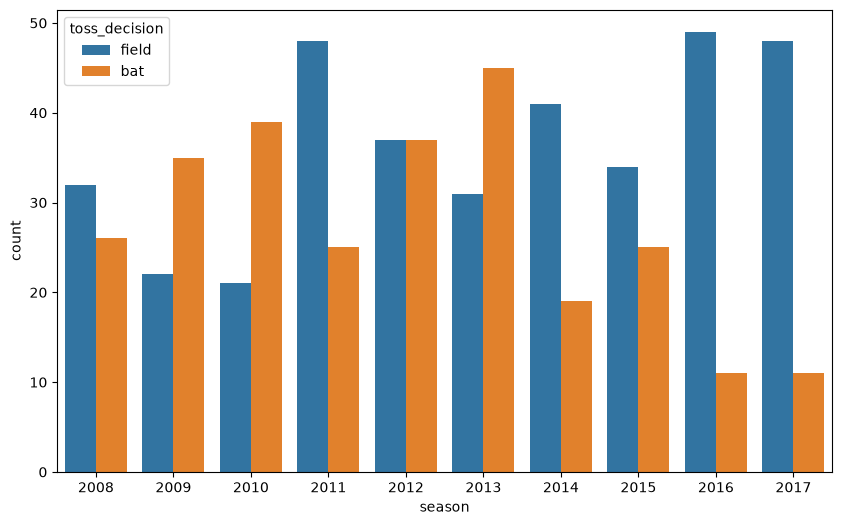

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.subplots(figsize = (10,6))
sns.countplot(x = 'season', hue = 'toss_decision', data = matches)
plt.show()

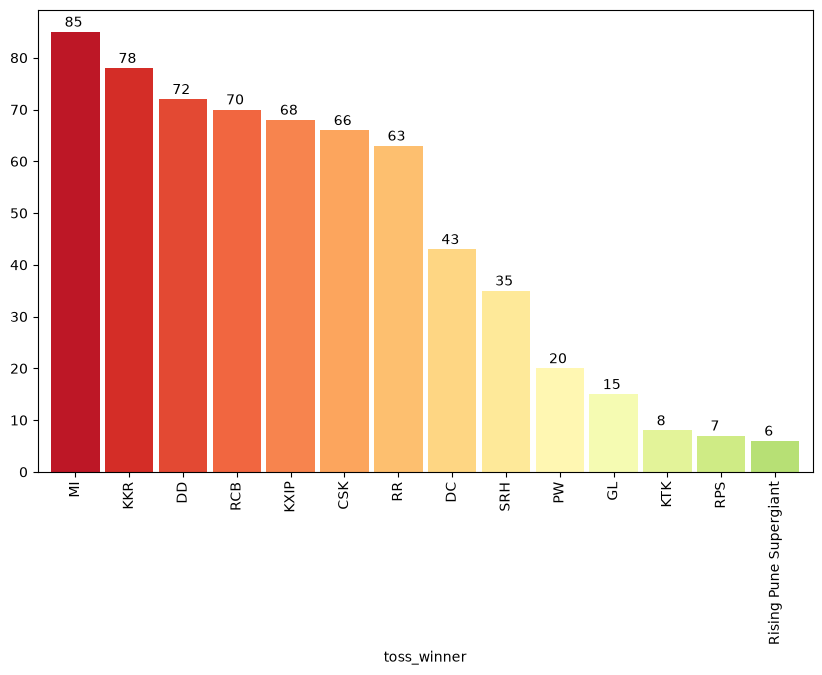

In [19]:
plt.subplots(figsize = (10,6))
ax = matches['toss_winner'].value_counts().plot.bar(width = 0.9, color = sns.color_palette('RdYlGn',20))
for p in ax.patches:
    ax.annotate(format(p.get_height()), (p.get_x()+0.25, p.get_height()+1))
plt.show()

                        Total Matches  wins
Team                                       
MI                                157    92
RCB                               152    73
KKR                               148    77
KXIP                              148    70
DD                                147    62
CSK                               131    79
RR                                118    63
SRH                                76    42
DC                                 75    29
PW                                 46    12
GL                                 30    13
Rising Pune Supergiant             16    10
KTK                                14     6
RPS                                14     5


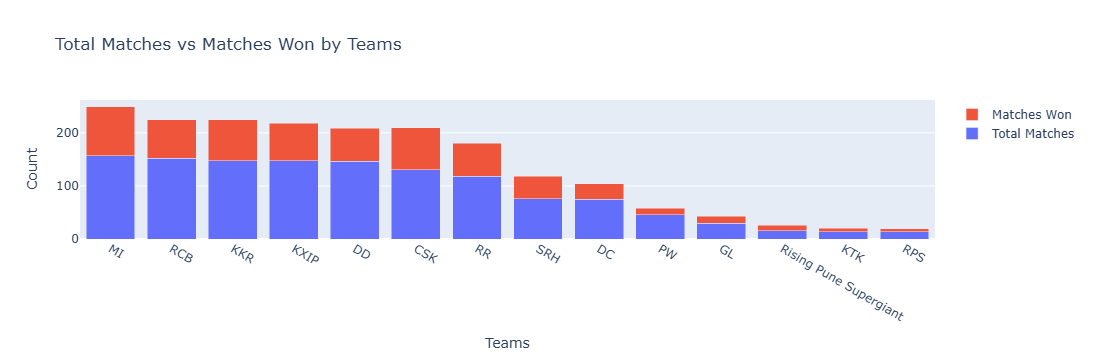

In [20]:
matches_played_byteams = pd.concat([matches['team1'], matches['team2']], axis=0)
matches_played_byteams = matches_played_byteams.value_counts().reset_index()
matches_played_byteams.columns = ['Team', 'Total Matches']

wins = matches['winner'].value_counts().reset_index()
wins.columns = ['Team', 'wins'] # Corrected column name to 'Team' for merging

matches_played_byteams = matches_played_byteams.merge(wins, on='Team', how='left')
matches_played_byteams.fillna(0, inplace=True) # Fill NaN for teams with no wins
matches_played_byteams.set_index('Team', inplace=True)

print(matches_played_byteams)

trace1 = go.Bar(
    x = matches_played_byteams.index,
    y = matches_played_byteams['Total Matches'],
    name = 'Total Matches'
)
trace2 = go.Bar(
    x = matches_played_byteams.index,
    y = matches_played_byteams['wins'],
    name = 'Matches Won'
)

data = [trace1, trace2]

layout = go.Layout(
    title = 'Total Matches vs Matches Won by Teams',
    xaxis = dict(title = 'Teams'),
    yaxis = dict(title = 'Count'),
    barmode = 'stack'
)

fig = go.Figure(data = data, layout = layout)
py.iplot(fig, filename = 'stacked-bar')

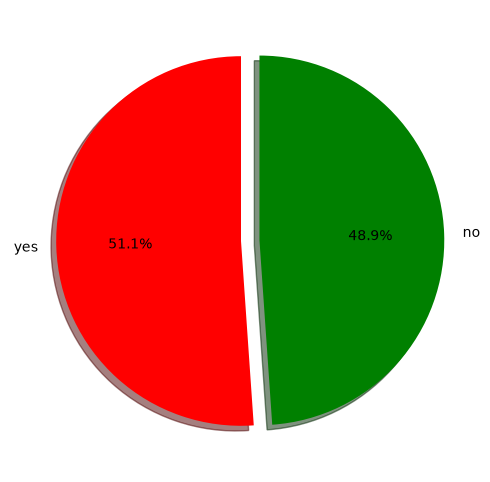

In [21]:
df = matches[matches['toss_winner'] == matches['winner']]

slices = [len(df), 636 - len(df)] # 636 is the total number of matches mentioned in the video
labels = ['yes', 'no']

plt.pie(slices, labels=labels, startangle=90, shadow=True, explode=(0, 0.1), autopct='%1.1f%%', colors=['r', 'g'])
fig = plt.gcf()
fig.set_size_inches(6, 6)
plt.show()

C:\Users\rmane\AppData\Local\Temp\ipykernel_23368\2764543792.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='season', data=matches, palette=sns.color_palette('winter'))
C:\Users\rmane\AppData\Local\Temp\ipykernel_23368\2764543792.py:2: UserWarning: 
The palette list has fewer values (6) than needed (10) and will cycle, which may produce an uninterpretable plot.
  sns.countplot(x='season', data=matches, palette=sns.color_palette('winter'))


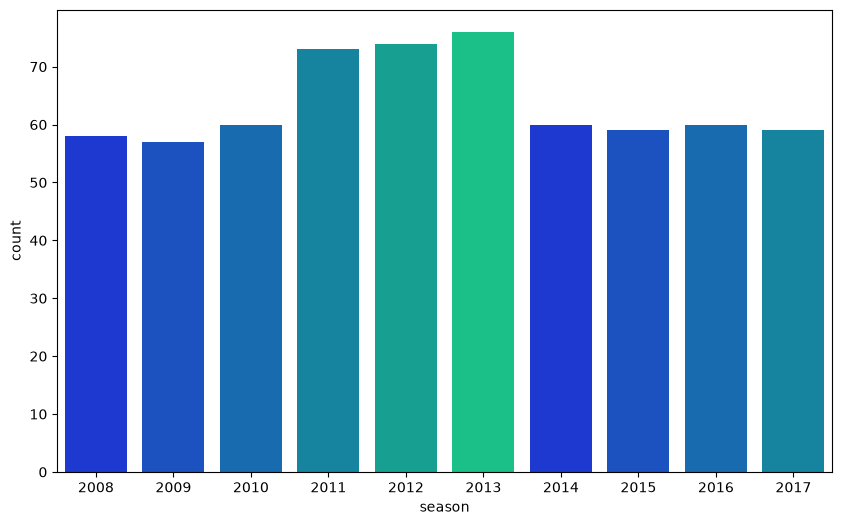

In [22]:
plt.subplots(figsize=(10, 6))
sns.countplot(x='season', data=matches, palette=sns.color_palette('winter'))
plt.show()

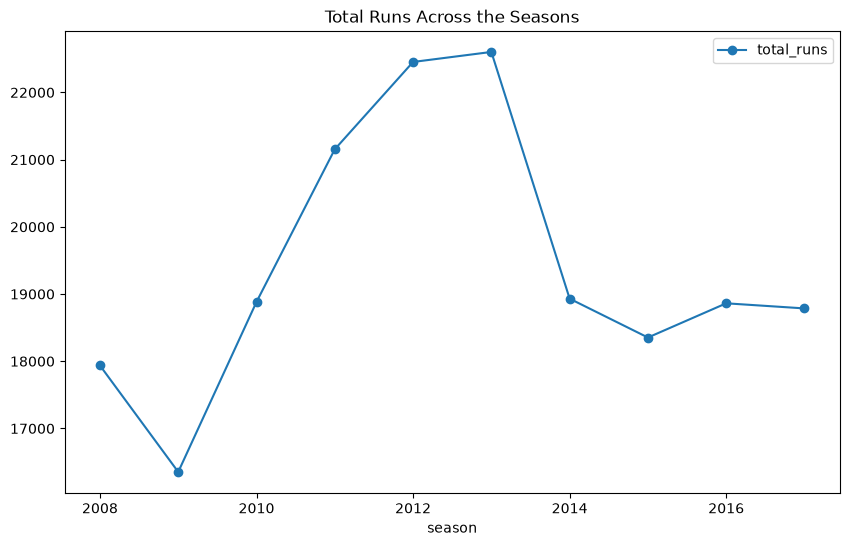

In [23]:
batsmen = matches[['id', 'season']].merge(delivery, left_on='id', right_on='match_id', how='left').drop('id', axis=1)

season_runs = batsmen.groupby(['season'])[['total_runs']].sum().reset_index()

season_runs.set_index('season').plot(marker='o')
plt.gcf().set_size_inches(10, 6)
plt.title('Total Runs Across the Seasons')
plt.show()

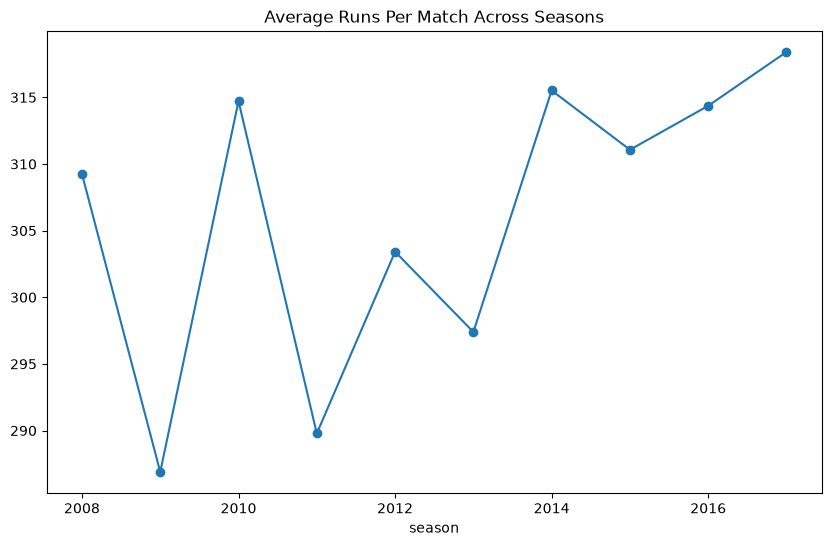

In [24]:
avgruns_each_season = matches.groupby(['season'])['id'].count().reset_index()
avgruns_each_season.rename(columns={'id':'matches'},inplace=True)

total_runs_per_season = matches[['id','season']].merge(delivery, left_on = 'id', right_on = 'match_id', how = 'left')
total_runs_per_season = total_runs_per_season.groupby(['season'])['total_runs'].sum().reset_index()

avgruns_each_season = avgruns_each_season.merge(total_runs_per_season, on='season', how='left')
avgruns_each_season['average_runs_per_match'] = avgruns_each_season['total_runs'] / avgruns_each_season['matches']

avgruns_each_season.set_index('season')['average_runs_per_match'].plot(marker='o')
plt.gcf().set_size_inches(10,6)
plt.title('Average Runs Per Match Across Seasons')
plt.show()

In [28]:
batsman = matches[['id', 'season']].merge(delivery, left_on='id', right_on='match_id', how='left').drop('id', axis=1)

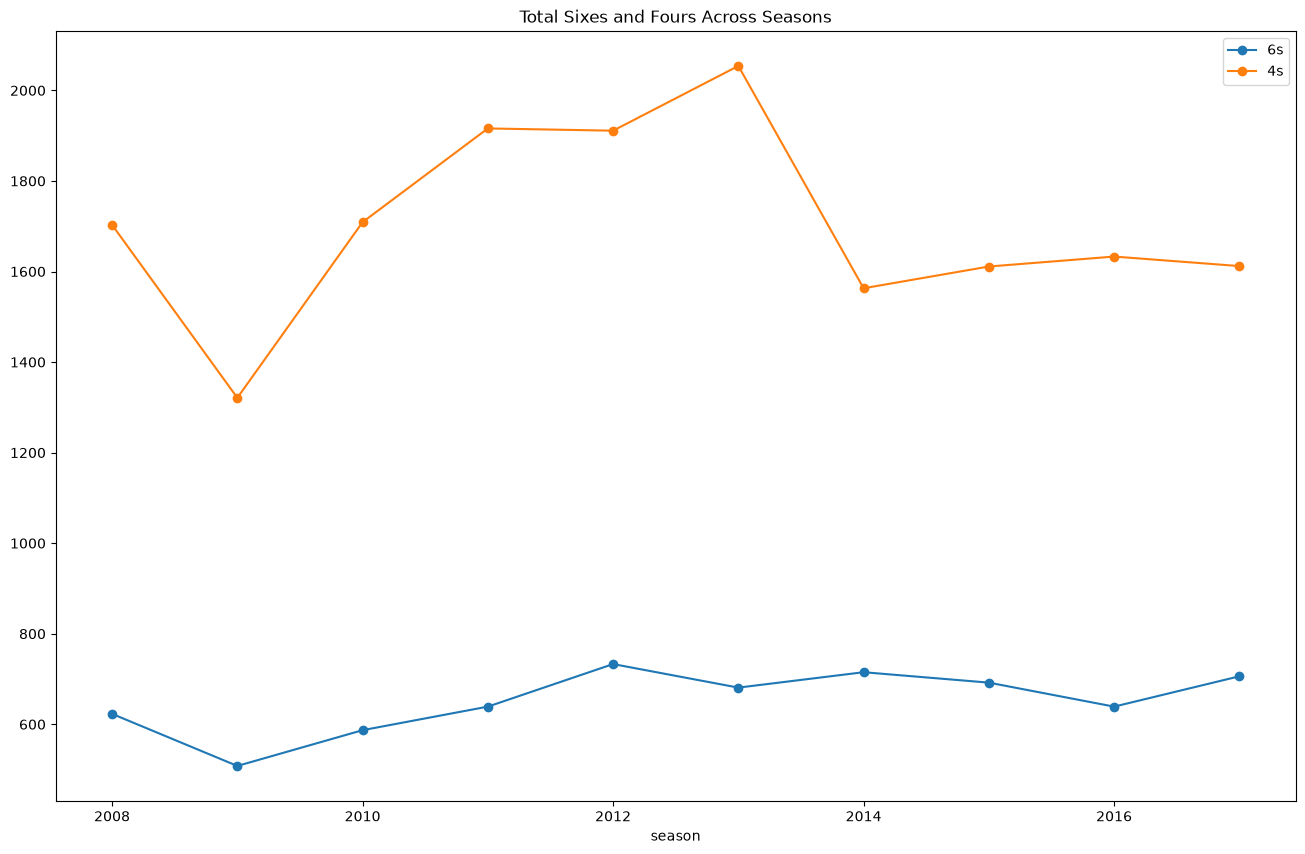

In [29]:
season_boundaries_sixes = batsman.groupby('season')['batsman_runs'].agg(lambda x: (x==6).sum()).reset_index()
season_boundaries_fours = batsman.groupby('season')['batsman_runs'].agg(lambda x: (x==4).sum()).reset_index()

season_boundaries = season_boundaries_sixes.merge(season_boundaries_fours, on='season', how='left')
season_boundaries.rename(columns={'batsman_runs_x':'6s','batsman_runs_y':'4s'},inplace=True)
season_boundaries.set_index('season')[['6s','4s']].plot(marker='o')
plt.gcf().set_size_inches(16,10)
plt.title('Total Sixes and Fours Across Seasons')
plt.show()

In [32]:
print(matches_played_byteams.columns.tolist())
print(matches_played_byteams.head())

['Total Matches', 'wins']
      Total Matches  wins
Team                     
MI              157    92
RCB             152    73
KKR             148    77
KXIP            148    70
DD              147    62


In [39]:
matches_played_byteams.columns = ['Team', 'Total Matches']

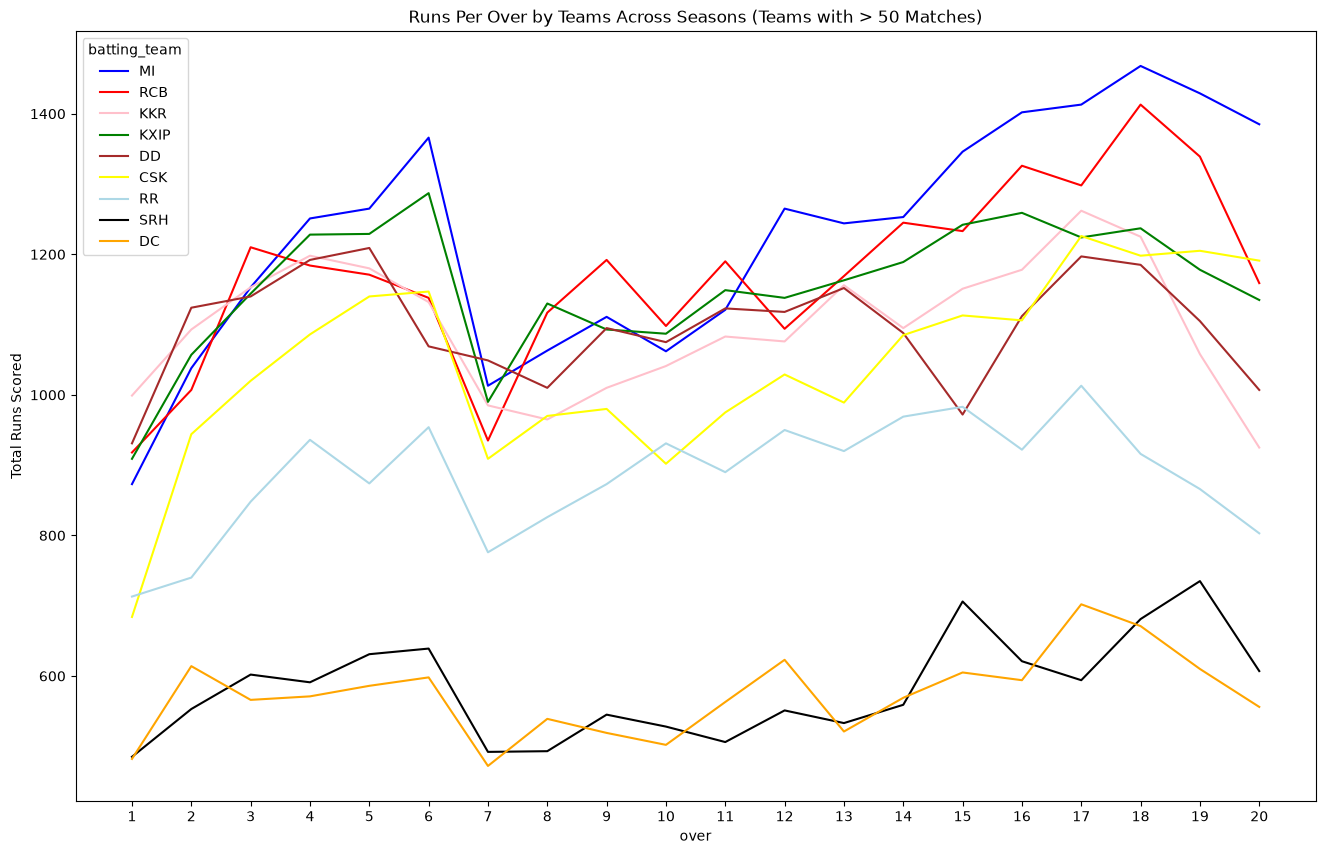

In [41]:
runs_per_over = delivery.pivot_table(index=['over'],columns=['batting_team'],values='total_runs',aggfunc=sum)

teams_gt_50_matches = matches_played_byteams[matches_played_byteams['Total Matches'] > 50]['Team'].tolist()

runs_per_over[teams_gt_50_matches].plot(color=['#0000FF','#FF0000','#FFC0CB','#008000','#A52A2A','#FFFF00','#ADD8E6','#000000','#FFA500'])
plt.xticks(list(range(1,21)))
plt.ylabel('Total Runs Scored')
plt.title('Runs Per Over by Teams Across Seasons (Teams with > 50 Matches)')
fig = plt.gcf()
fig.set_size_inches(16,10)
plt.show()

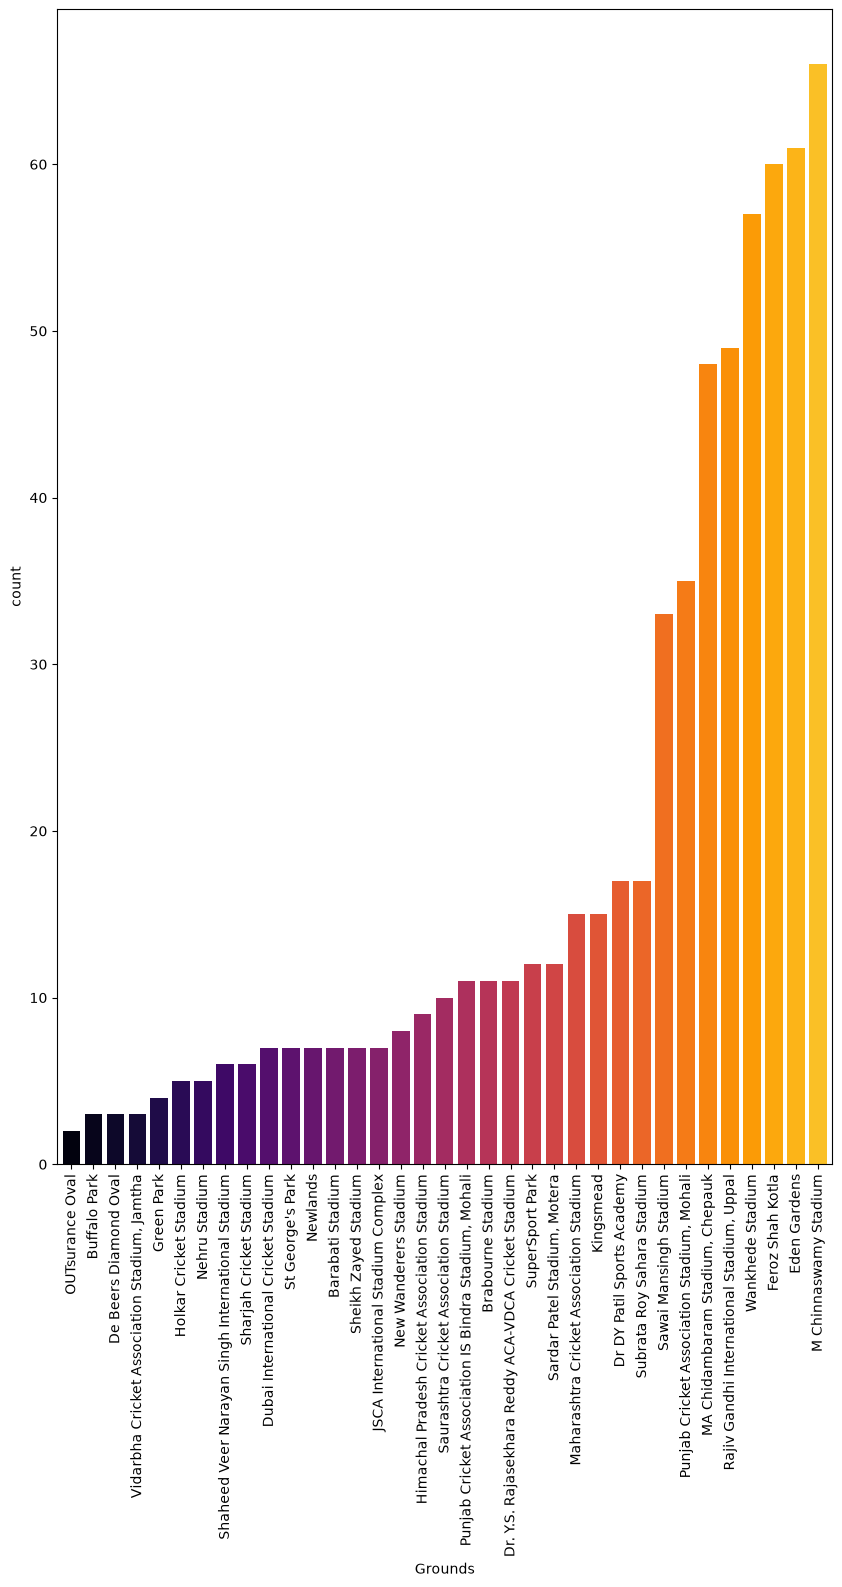

In [42]:
plt.subplots(figsize=(10, 15))
ax = matches['venue'].value_counts().sort_values(ascending=True).plot.bar(width=0.8, color=sns.color_palette('inferno', 40))
ax.set_xlabel(' Grounds ')
ax.set_ylabel('count')
plt.show()

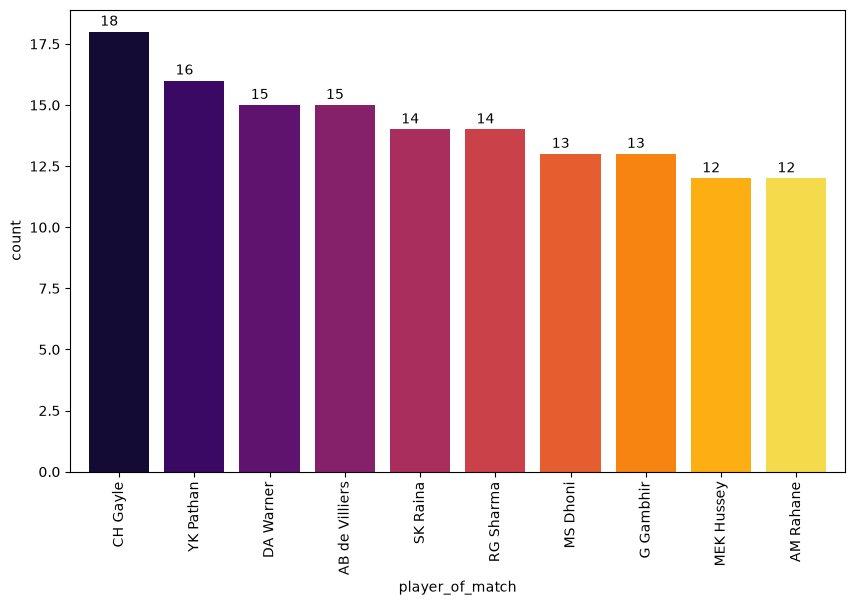

In [43]:
plt.subplots(figsize=(10, 6))
ax = matches['player_of_match'].value_counts().head(10).plot.bar(width=0.8, color=sns.color_palette('inferno', 10))
ax.set_xlabel('player_of_match')
ax.set_ylabel('count')
for p in ax.patches:
    ax.annotate(format(p.get_height()), (p.get_x() + 0.15, p.get_height() + 0.25))
plt.show()

In [45]:
print('Total Matches with Super Overs:')
print(delivery[delivery['is_super_over'] == 1].match_id.nunique())

Total Matches with Super Overs:
7


In [46]:
teams = ['MI', 'CSK', 'KKR', 'RCB', 'RR', 'KXIP', 'DD', 'SRH', 'PW', 'RPS', 'GL', 'KTK', 'DC', 'PWI', 'Kochi Tuskers Kerala', 'Pune Warriors', 'Rising Pune Supergiants', 'Gujarat Lions', 'Deccan Chargers', 'Delhi Daredevils', 'Kings XI Punjab', 'Royal Challengers Bangalore', 'Rajasthan Royals', 'Kolkata Knight Riders', 'Chennai Super Kings', 'Mumbai Indians', 'Sunrisers Hyderabad'] # Example list, ensure it's complete

play = delivery[delivery['is_super_over'] == 1].batting_team.unique()
play = list(play)
print('Teams who haven\'t ever played a super over are: ', list(set(teams) - set(play)))

Teams who haven't ever played a super over are:  ['Deccan Chargers', 'Mumbai Indians', 'Rising Pune Supergiants', 'PW', 'PWI', 'RPS', 'Pune Warriors', 'Royal Challengers Bangalore', 'Sunrisers Hyderabad', 'Kolkata Knight Riders', 'Gujarat Lions', 'Rajasthan Royals', 'Kochi Tuskers Kerala', 'Delhi Daredevils', 'DC', 'KTK', 'Kings XI Punjab', 'Chennai Super Kings']


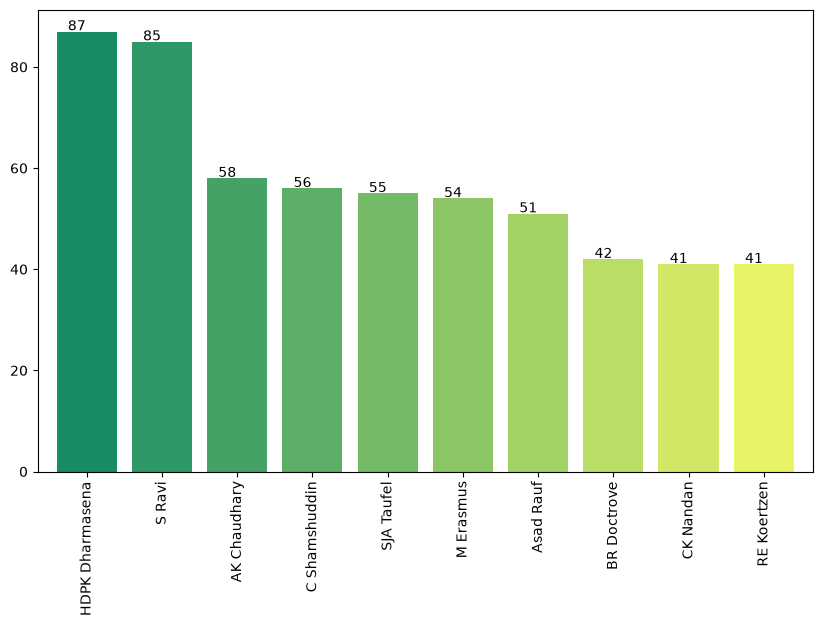

In [47]:
plt.subplots(figsize=(10, 6))
ump = pd.concat([matches['umpire1'], matches['umpire2']])
ax = ump.value_counts().head(10).plot.bar(width=0.8, color=sns.color_palette('summer', 10))
for p in ax.patches:
    ax.annotate(format(p.get_height()), (p.get_x() + 0.15, p.get_height() + 0.25))
plt.show()

In [1]:
def team_vs_team2(team1, team2):
    nt1 = matches[
        ((matches['team1'] == team1) | (matches['team2'] == team1)) &
        ((matches['team1'] == team2) | (matches['team2'] == team2))
    ]
    sns.countplot(x='season', hue='winner', data=nt1, palette='Set3')
    plt.xticks(rotation='vertical')
    leg = plt.legend(loc='upper center')
    fig = plt.gcf()
    fig.set_size_inches(10, 6)
    plt.show()

In [2]:
def comparator(team1):
    teams = ['MI', 'CSK', 'KKR', 'RCB', 'RR', 'KXIP', 'DD', 'SRH', 'PW', 'RPS', 'GL', 'KTK', 'DC', 'PWI'] 
    teams.remove(team1)
    opponents = teams.copy()

    mt1 = matches[
        (matches['team1'] == team1) | (matches['team2'] == team1)
    ]

    for i in opponents:
        mask = (
            ((mt1['team1'] == i) | (mt1['team2'] == i)) &
            ((mt1['team1'] == team1) | (mt1['team2'] == team1))
        )
        mt2 = mt1.loc[mask, 'winner'].value_counts().to_frame()
        if not mt2.empty: # Only print if there are matches found
            print(f"\nHead-to-head between {team1} and {i}:")
            print(mt2)



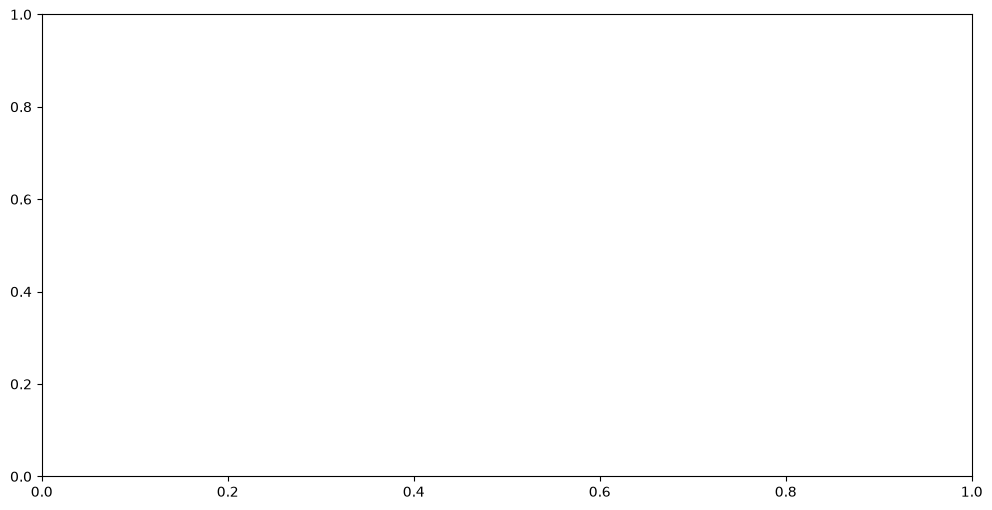

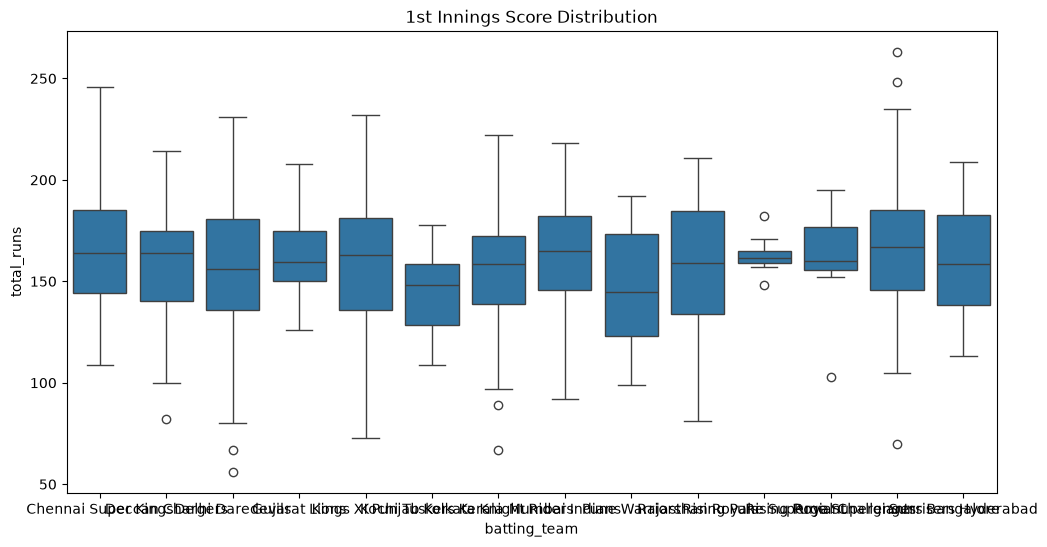

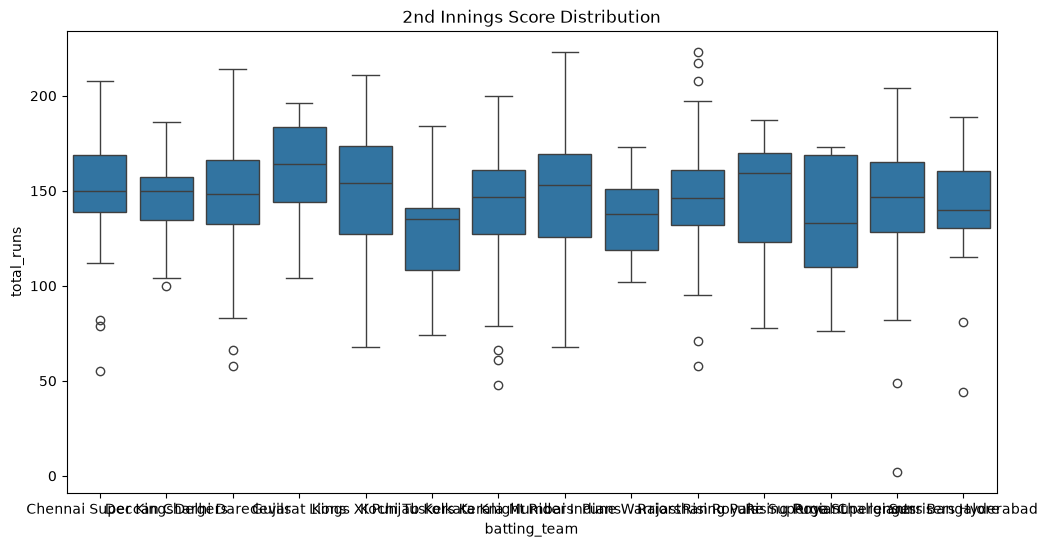

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
delivery = pd.read_csv('deliveries.csv')
plt.subplots(figsize=(12, 6))
xyz = delivery.groupby(['match_id', 'inning', 'batting_team'])['total_runs'].sum().reset_index()
xyz.drop(['match_id'], axis=1, inplace=True)
xyz.sort_values(by=['batting_team', 'total_runs'], ascending=True, inplace=True)

score_1_inning = xyz[xyz['inning'] == 1]
score_2_inning = xyz[xyz['inning'] == 2]

plt.figure(figsize=(12, 6)) # Create a new figure for the first plot
sns.boxplot(x='batting_team', y='total_runs', data=score_1_inning)
plt.title('1st Innings Score Distribution')
plt.show()

plt.figure(figsize=(12, 6)) # Create a new figure for the second plot
sns.boxplot(x='batting_team', y='total_runs', data=score_2_inning)
plt.title('2nd Innings Score Distribution')
plt.show()

In [8]:
high_scores = delivery.groupby(['match_id', 'inning', 'batting_team', 'bowling_team'])['total_runs'].sum().reset_index()
high_scores = high_scores[high_scores['total_runs'] >= 200]
print("Matches with 200+ scores (Top 10):")
print(high_scores.nlargest(10, 'total_runs'))

Matches with 200+ scores (Top 10):
      match_id  inning                 batting_team  \
829        411       1  Royal Challengers Bangalore   
1250       620       1  Royal Challengers Bangalore   
416        206       1          Chennai Super Kings   
122         61       1          Chennai Super Kings   
1134       562       1  Royal Challengers Bangalore   
596        296       1              Kings XI Punjab   
522        259       1             Delhi Daredevils   
981        486       1              Kings XI Punjab   
100         50       1              Kings XI Punjab   
1170       580       1  Royal Challengers Bangalore   

                     bowling_team  total_runs  
829                 Pune Warriors         263  
1250                Gujarat Lions         248  
416              Rajasthan Royals         246  
122               Kings XI Punjab         240  
1134               Mumbai Indians         235  
596   Royal Challengers Bangalore         232  
522               Kings

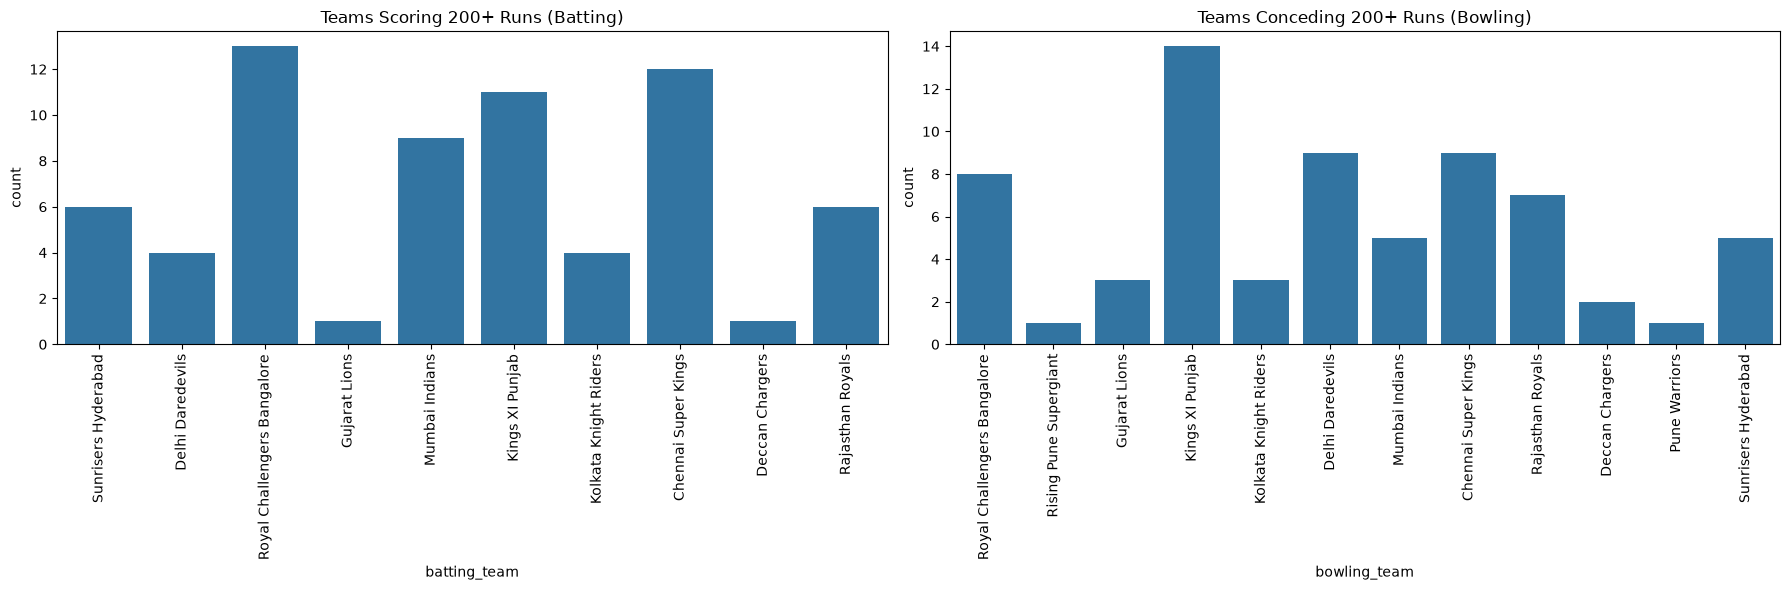

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(18, 6))
sns.countplot(x=high_scores['batting_team'], ax=ax[0])
ax[0].set_title('Teams Scoring 200+ Runs (Batting)')
ax[0].tick_params(axis='x', rotation=90)

sns.countplot(x=high_scores['bowling_team'], ax=ax[1])
ax[1].set_title('Teams Conceding 200+ Runs (Bowling)')
ax[1].tick_params(axis='x', rotation=90)

plt.tight_layout() 
plt.show()

In [12]:
import pandas as pd
import numpy as np
all_teams = ['MI', 'CSK', 'KKR', 'RCB', 'RR', 'KXIP', 'DD', 'SRH', 'PW', 'RPS', 'GL', 'KTK', 'DC', 'PWI', 'Kochi Tuskers Kerala', 'Pune Warriors', 'Rising Pune Supergiants', 'Gujarat Lions', 'Deccan Chargers', 'Delhi Daredevils', 'Kings XI Punjab', 'Royal Challengers Bangalore', 'Rajasthan Royals', 'Kolkata Knight Riders', 'Chennai Super Kings', 'Mumbai Indians', 'Sunrisers Hyderabad']

teams_scored_200_plus = set(high_scores['batting_team'].unique())
teams_not_scored_200_plus = list(set(all_teams) - teams_scored_200_plus)
print("Teams who have not scored over 200 runs are:", teams_not_scored_200_plus)

teams_conceded_200_plus = set(high_scores['bowling_team'].unique())
teams_not_conceded_200_plus = list(set(all_teams) - teams_conceded_200_plus)
print("Teams who have not conceded over 200 runs are:", teams_not_conceded_200_plus)

Teams who have not scored over 200 runs are: ['PW', 'DC', 'GL', 'RCB', 'Pune Warriors', 'KXIP', 'Kochi Tuskers Kerala', 'SRH', 'DD', 'KKR', 'MI', 'CSK', 'RR', 'Rising Pune Supergiants', 'RPS', 'KTK', 'PWI']
Teams who have not conceded over 200 runs are: ['PW', 'DC', 'GL', 'RCB', 'KXIP', 'Kochi Tuskers Kerala', 'SRH', 'DD', 'KKR', 'MI', 'CSK', 'RR', 'Rising Pune Supergiants', 'RPS', 'KTK', 'PWI']


In [13]:
import pandas as pd
import numpy as np
high = delivery.groupby(['match_id', 'inning', 'batting_team', 'bowling_team'])['total_runs'].sum().reset_index()

high_scores1 = high[high['inning'] == 1]
high_scores2 = high[high['inning'] == 2]

merged_scores = pd.merge(high_scores1, high_scores2, on='match_id', suffixes=('_1', '_2'))

merged_scores.rename(columns={
    'inning_1': 'inning1',
    'batting_team_1': 'batting_team1',
    'bowling_team_1': 'bowling_team1',
    'total_runs_1': 'innings1_runs',
    'inning_2': 'inning2',
    'batting_team_2': 'batting_team2',
    'bowling_team_2': 'bowling_team2',
    'total_runs_2': 'innings2_runs'
}, inplace=True)
chasing_analysis = merged_scores[merged_scores['innings1_runs'] >= 200]

# Determine if the score was chased
chasing_analysis['is_score_chased'] = np.where(
    chasing_analysis['innings2_runs'] >= chasing_analysis['innings1_runs'],
    'Yes', 'No'
)

print("Analysis of 200+ scores and chasing success:")
print(chasing_analysis[['match_id', 'batting_team1', 'innings1_runs', 'batting_team2', 'innings2_runs', 'is_score_chased']].head())

Analysis of 200+ scores and chasing success:
    match_id                batting_team1  innings1_runs  \
0          1          Sunrisers Hyderabad            207   
8          9             Delhi Daredevils            205   
19        20  Royal Challengers Bangalore            213   
31        32          Sunrisers Hyderabad            207   
35        36          Sunrisers Hyderabad            209   

                  batting_team2  innings2_runs is_score_chased  
0   Royal Challengers Bangalore            172              No  
8        Rising Pune Supergiant            108              No  
19                Gujarat Lions            192              No  
31              Kings XI Punjab            181              No  
35        Kolkata Knight Riders            161              No  


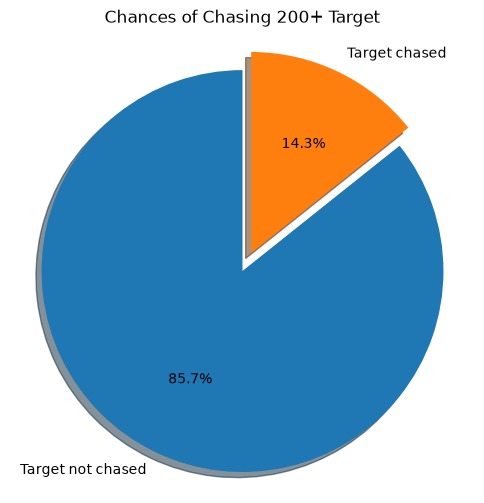

In [14]:
slices = chasing_analysis['is_score_chased'].value_counts()
labels = ['Target not chased', 'Target chased']
colors = ['#1f77b4', '#ff7f0e'] 
explode = (0.1, 0) 

plt.figure(figsize=(6, 6))
plt.pie(slices, labels=labels, colors=colors, startangle=90, shadow=True, explode=explode, autopct='%1.1f%%')
plt.title('Chances of Chasing 200+ Target')
plt.axis('equal') 
plt.show()

In [15]:
balls_faced = delivery.groupby('batsman')['ball'].count().reset_index()
balls_faced.rename(columns={'ball': 'balls_faced'}, inplace=True)

batsman_runs_df = delivery.groupby('batsman')['batsman_runs'].sum().reset_index()


batsman_stats = pd.merge(balls_faced, batsman_runs_df, on='batsman', how='outer')


fours_df = delivery[delivery['batsman_runs'] == 4].groupby('batsman')['batsman_runs'].count().reset_index()
fours_df.rename(columns={'batsman_runs': 'fours'}, inplace=True)

sixes_df = delivery[delivery['batsman_runs'] == 6].groupby('batsman')['batsman_runs'].count().reset_index()
sixes_df.rename(columns={'batsman_runs': 'sixes'}, inplace=True)
batsman_stats['strike_rate'] = (batsman_stats['batsman_runs'] / batsman_stats['balls_faced']) * 100

batsman_stats = pd.merge(batsman_stats, fours_df, on='batsman', how='outer').fillna(0) # Fill NaN with 0 for players with no fours
batsman_stats = pd.merge(batsman_stats, sixes_df, on='batsman', how='outer').fillna(0) # Fill NaN with 0 for players with no sixes
highest_score_per_match_team = delivery.groupby(['match_id', 'batsman', 'batting_team'])['batsman_runs'].sum().reset_index()

highest_score_overall = highest_score_per_match_team.groupby('batsman')['batsman_runs'].max().reset_index()
highest_score_overall.rename(columns={'batsman_runs': 'highest_score'}, inplace=True)
batsman_stats = pd.merge(batsman_stats, highest_score_overall, on='batsman', how='outer')


teams_played = delivery.groupby('batsman')['batting_team'].unique().apply(list).reset_index()
teams_played.rename(columns={'batting_team': 'teams'}, inplace=True)
batsman_stats = pd.merge(batsman_stats, teams_played, on='batsman', how='outer')

print(batsman_stats.head())

          batsman  balls_faced  batsman_runs  strike_rate  fours  sixes  \
0  A Ashish Reddy          196           280   142.857143   16.0   15.0   
1      A Chandila            7             4    57.142857    0.0    0.0   
2        A Chopra           75            53    70.666667    7.0    0.0   
3     A Choudhary           20            25   125.000000    1.0    1.0   
4      A Flintoff           57            62   108.771930    5.0    2.0   

   highest_score                                   teams  
0             36  [Deccan Chargers, Sunrisers Hyderabad]  
1              4                      [Rajasthan Royals]  
2             24                 [Kolkata Knight Riders]  
3             15           [Royal Challengers Bangalore]  
4             24                   [Chennai Super Kings]  


IndexError: single positional indexer is out-of-bounds

<Figure size 1500x1200 with 0 Axes>

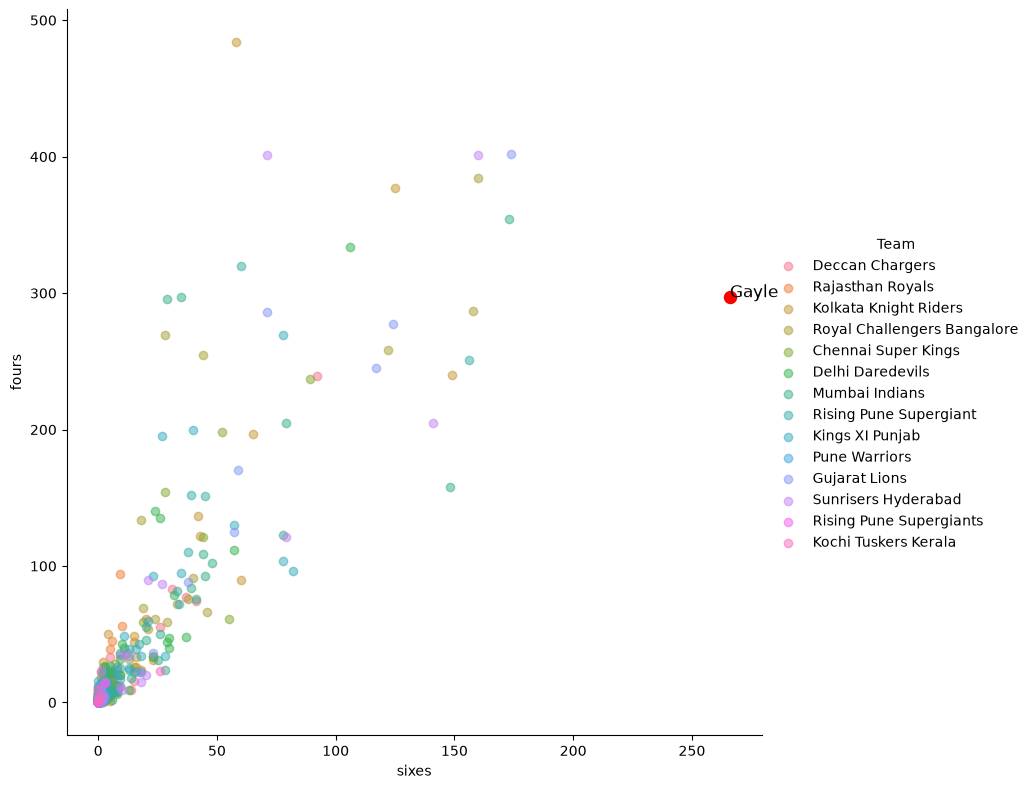

In [17]:
try:
    balls = batsman_stats.copy() 
    
    if 'teams' in balls.columns:
        balls['Team'] = balls['teams'].apply(lambda x: x[0] if isinstance(x, list) and len(x) > 0 else 'Unknown')
    else:
        balls['Team'] = 'Dummy Team'
except NameError:
    print("Please ensure 'batsman_stats' DataFrame is defined (from previous video's data preparation).")
    # Create a minimal dummy for demonstration if batsman_stats is not found
    data = {
        'batsman': ['CH Gayle', 'AB de Villiers', 'MS Dhoni', 'V Kohli', 'SK Raina', 'RG Sharma'],
        'sixes': [300, 200, 150, 180, 100, 120],
        'fours': [400, 350, 280, 450, 320, 300],
        'batsman_runs': [5000, 4500, 4000, 5500, 4800, 4200],
        'balls_faced': [3000, 2500, 2800, 3200, 3100, 2900],
        'strike_rate': [166.6, 180.0, 142.8, 171.8, 154.8, 144.8],
        'Team': ['RCB', 'RCB', 'CSK', 'RCB', 'CSK', 'MI']
    }
    balls = pd.DataFrame(data)
    balls['teams'] = balls['Team'].apply(lambda x: [x]) # For compatibility if teams column was expected

def batsman_comparator(stat1, stat2, batsman1, batsman2):
    plt.figure(figsize=(15, 12)) # Create a figure for the plot
    sns.FacetGrid(balls, hue='Team', height=8).map(plt.scatter, stat1, stat2, alpha=0.5).add_legend()


    bats1 = balls[balls['batsman'].str.contains(batsman1, na=False)]
    bats1 = bats1.sort_values(by=stat1, ascending=False)

    
    bats2 = balls[balls['batsman'].str.contains(batsman2, na=False)]
    bats2 = bats2.sort_values(by=stat1, ascending=False)

    
    plt.scatter(bats1[stat1], bats1[stat2], s=75, c='red', label=batsman1)
    plt.annotate(batsman1, (bats1[stat1].iloc[0], bats1[stat2].iloc[0]), fontsize=12)

    plt.scatter(bats2[stat1], bats2[stat2], s=75, c='#4f73a5', label=batsman2)
    plt.annotate(batsman2, (bats2[stat1].iloc[0], bats2[stat2].iloc[0]), fontsize=12)

    plt.title(f'Batsman Comparator: {stat1} vs {stat2}', size=25)
    plt.xlabel(stat1)
    plt.ylabel(stat2)
    plt.legend()
    plt.show()


batsman_comparator('sixes', 'fours', 'Gayle', 'De Villiers')


batsman_comparator('batsman_runs', 'strike_rate', 'Dhoni', 'V Kohli')


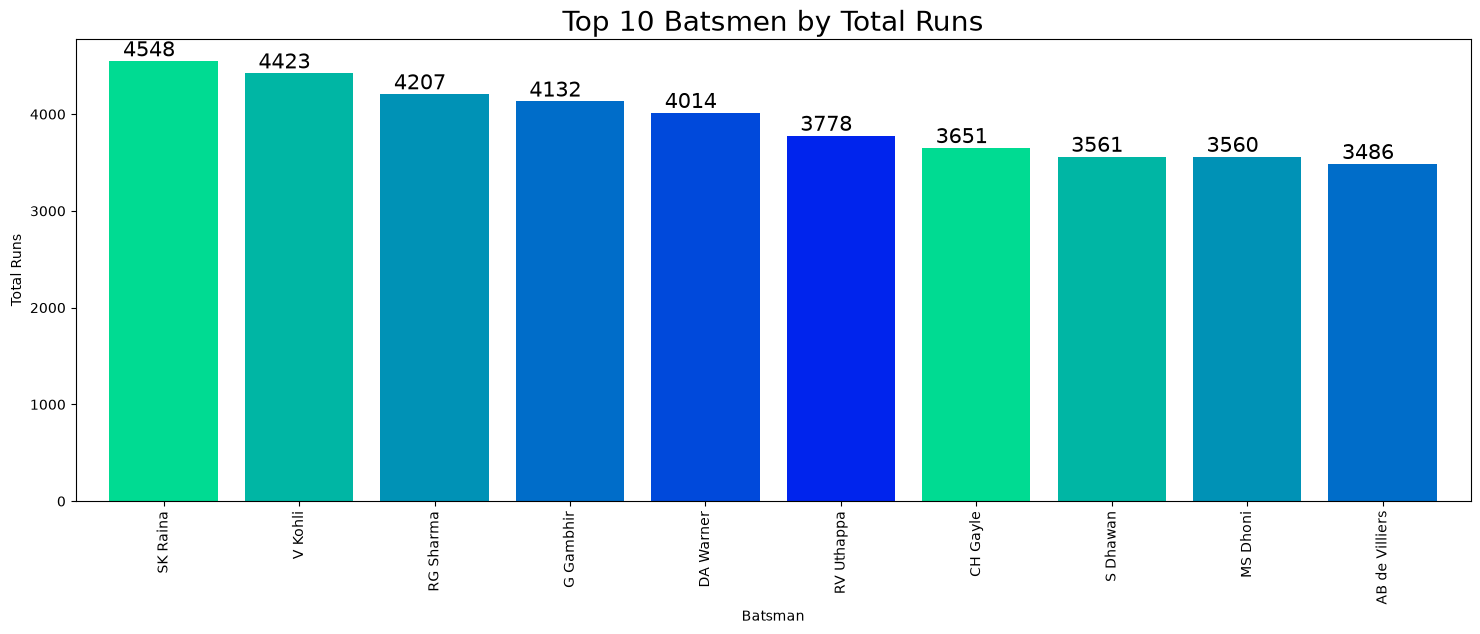

In [18]:
plt.subplots(figsize=(18, 6))

max_runs = delivery.groupby(['batsman'])['batsman_runs'].sum()


ax = max_runs.sort_values(ascending=False)[:10].plot.bar(width=0.8, color=sns.color_palette('winter_r'))


for p in ax.patches:
    ax.annotate(format(p.get_height()), (p.get_x() + 0.1, p.get_height() + 50), fontsize=15)

plt.title('Top 10 Batsmen by Total Runs', size=20)
plt.xlabel('Batsman')
plt.ylabel('Total Runs')
plt.show()

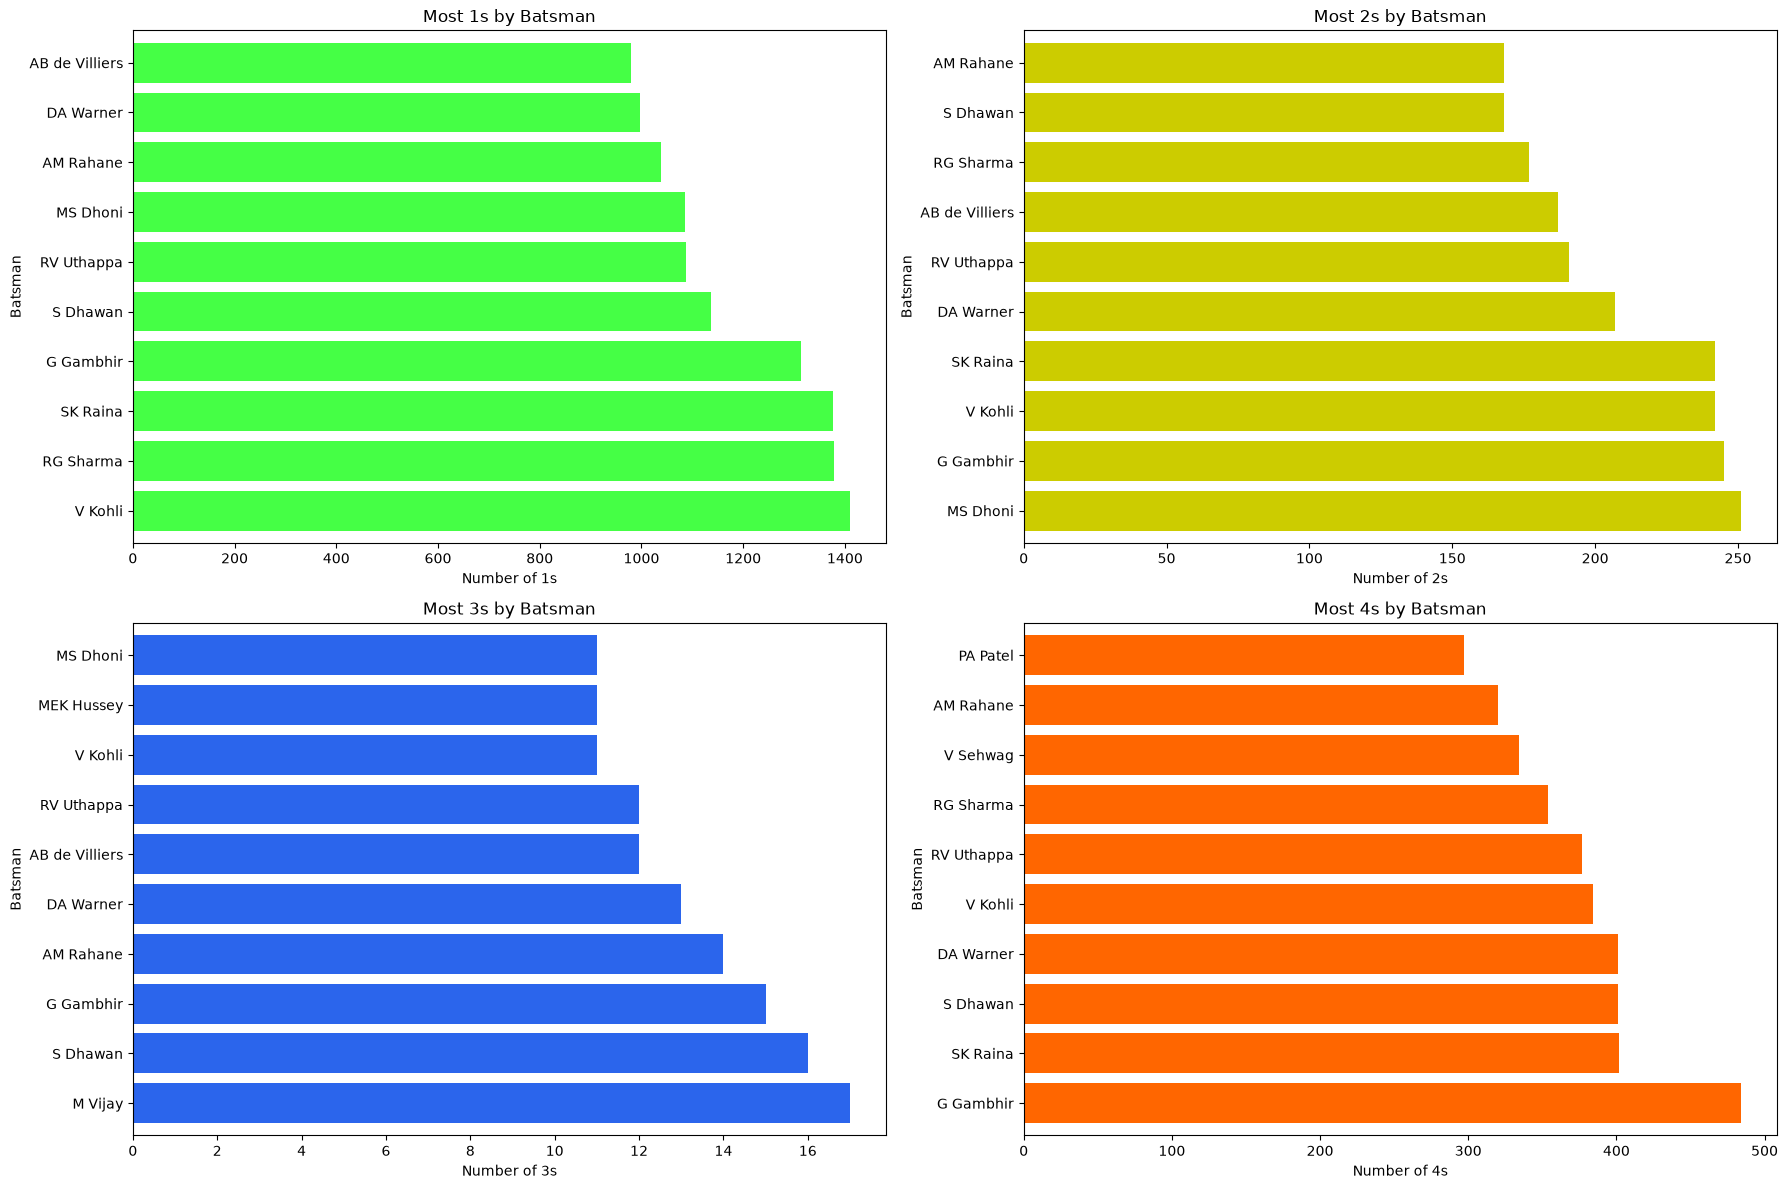

In [19]:
toppers = delivery.groupby(['batsman', 'batsman_runs'])['batsman_runs'].count().reset_index(name='count')

# Pivot the table to have batsman_runs (1, 2, 3, 4, 6) as columns
toppers = toppers.pivot(index='batsman', columns='batsman_runs', values='count').fillna(0)

# Create subplots
fig, ax = plt.subplots(2, 2, figsize=(18, 12))

# Plot for 1s
toppers[1].sort_values(ascending=False).head(10).plot(kind='barh', ax=ax[0, 0], color='#45ff45', width=0.8)
ax[0, 0].set_title('Most 1s by Batsman')
ax[0, 0].set_xlabel('Number of 1s')
ax[0, 0].set_ylabel('Batsman')

# Plot for 2s
toppers[2].sort_values(ascending=False).head(10).plot(kind='barh', ax=ax[0, 1], color='#CCCC00', width=0.8)
ax[0, 1].set_title('Most 2s by Batsman')
ax[0, 1].set_xlabel('Number of 2s')
ax[0, 1].set_ylabel('Batsman')

# Plot for 3s
toppers[3].sort_values(ascending=False).head(10).plot(kind='barh', ax=ax[1, 0], color='#2B65EC', width=0.8)
ax[1, 0].set_title('Most 3s by Batsman')
ax[1, 0].set_xlabel('Number of 3s')
ax[1, 0].set_ylabel('Batsman')

# Plot for 4s
toppers[4].sort_values(ascending=False).head(10).plot(kind='barh', ax=ax[1, 1], color='#FF6600', width=0.8)
ax[1, 1].set_title('Most 4s by Batsman')
ax[1, 1].set_xlabel('Number of 4s')
ax[1, 1].set_ylabel('Batsman')

plt.tight_layout()
plt.show()

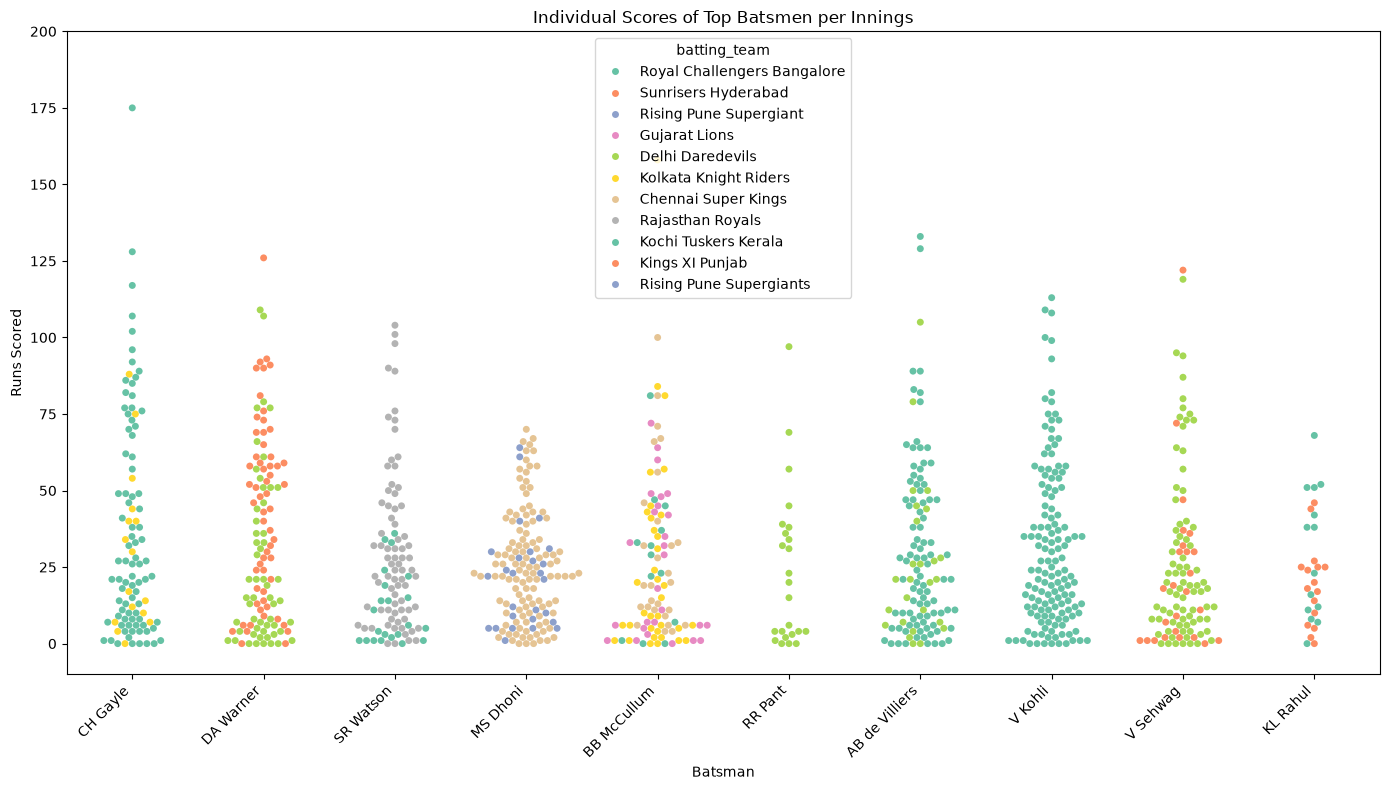

In [20]:
top_scores = delivery.groupby(['match_id', 'batsman', 'batting_team'])['batsman_runs'].sum().reset_index()


swam = ['CH Gayle', 'BB McCullum', 'AB de Villiers', 'DA Warner', 'V Sehwag', 'RR Pant', 'MS Dhoni', 'KL Rahul', 'SR Watson', 'V Kohli']

scores = delivery.groupby(['match_id', 'batsman', 'batting_team'])['batsman_runs'].sum().reset_index()
scores = scores[scores['batsman'].isin(swam)]

plt.figure(figsize=(14, 8))
sns.swarmplot(x='batsman', y='batsman_runs', data=scores, hue='batting_team', palette='Set2')
plt.ylim(-10, 200) # Adjust y-axis limit to include zeros and beyond max score
plt.title('Individual Scores of Top Batsmen per Innings')
plt.xlabel('Batsman')
plt.ylabel('Runs Scored')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [21]:
a = delivery.groupby(['season', 'batsman'])['batsman_runs'].sum().reset_index()
a = a.pivot(index='season', columns='batsman', values='batsman_runs').fillna(0)

# Calculate total runs for each batsman across all seasons
a['Total'] = a.sum(axis=1) # This sums up all batsmen's runs per season, not per batsman across seasons

# To get total runs per batsman across all seasons for sorting:
batsman_total_runs = delivery.groupby('batsman')['batsman_runs'].sum().reset_index()
top_5_batsmen = batsman_total_runs.sort_values(by='batsman_runs', ascending=False).head(5)['batsman'].tolist()

# Filter the seasonal data for top 5 batsmen and re-calculate 'a' for plotting
a = delivery.groupby(['season', 'batsman'])['batsman_runs'].sum().reset_index()
a = a[a['batsman'].isin(top_5_batsmen)]
a = a.pivot(index='season', columns='batsman', values='batsman_runs').fillna(0)

# Plotting the runs scored by top batsmen across seasons
fig = plt.figure(figsize=(16, 6))
a.plot(kind='line', ax=fig.gca(), marker='o', linewidth=2)
plt.title('Runs Scored by Top Batsmen Across Seasons')
plt.xlabel('Season')
plt.ylabel('Runs Scored')
plt.legend(title='Batsman', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

KeyError: 'season'

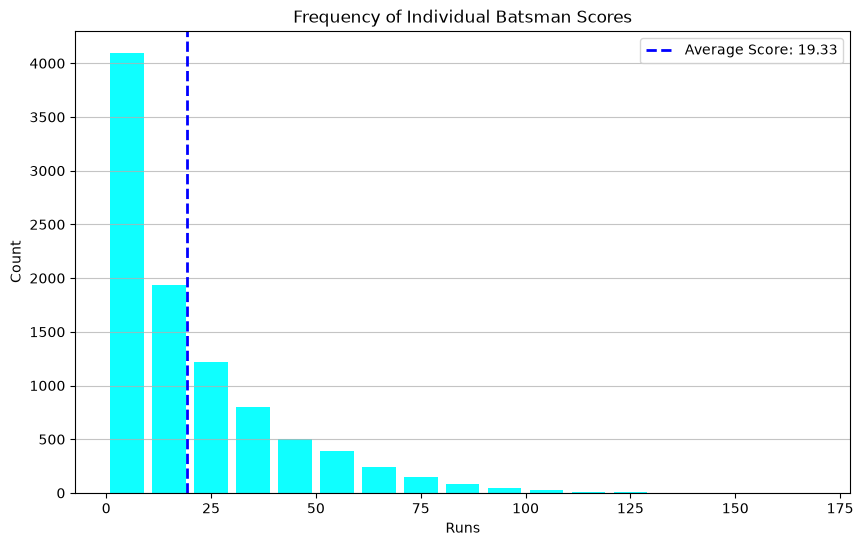

In [22]:
top_scores_for_hist = delivery.groupby(['match_id', 'batsman', 'batting_team'])['batsman_runs'].sum().reset_index()

plt.figure(figsize=(10, 6))
bins = range(0, 180, 10) # Bins from 0 to 180 with a step of 10
plt.hist(top_scores_for_hist['batsman_runs'], bins, histtype='bar', rwidth=0.8, color='#0FFFFF') # Changed rwidth for better visual
plt.xlabel('Runs')
plt.ylabel('Count')
plt.title('Frequency of Individual Batsman Scores')

# Calculate and plot the mean
mean_score = top_scores_for_hist['batsman_runs'].mean()
plt.axvline(mean_score, color='b', linestyle='dashed', linewidth=2, label=f'Average Score: {mean_score:.2f}')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()